In [1]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from src.preprocessing.pipeline import FORECAST_COLS, NEW_FEATS
from src.models.evaluate import evaluate
from src.models.train import EXPERIMENTS, load_dataset, split, feature_sets, run_experiment, save_model

df, data = load_dataset("../data/raw/energy_dataset.csv")
print(df.shape, data.shape)

(35064, 20) (34871, 21)


In [2]:
X_train, y_train, X_test, y_test = split(data)
fsets = feature_sets(X_train)
print(X_train.shape, X_test.shape)
print("v1:", len(fsets["v1"]), fsets["v1"])
print("v2 adds:", NEW_FEATS)

(26112, 20) (8759, 20)
v1: 18 ['price_lag_24', 'price_lag_48', 'price_lag_72', 'price_lag_168', 'price_ma_24', 'price_ma_168', 'total load actual_lag_24', 'generation fossil gas_lag_24', 'generation fossil hard coal_lag_24', 'generation wind onshore_lag_24', 'generation solar_lag_24', 'total load forecast', 'forecast solar day ahead', 'forecast wind onshore day ahead', 'hour', 'dayofweek', 'is_weekend', 'month']
v2 adds: ['residual_load_forecast', 'is_holiday']


In [3]:
baselines = {
    "Baseline: same hour yesterday": X_test["price_lag_24"],
    "Baseline: same hour last week": X_test["price_lag_168"],
    "Benchmark: market day-ahead price": df.loc[X_test.index, "price day ahead"],
}
rows = [{"experiment": n, "features": "-", **evaluate(y_test, p)} for n, p in baselines.items()]
pd.DataFrame(rows)

,experiment,features,MAE,RMSE,R2
0,Baseline: same hour yesterday,-,5.205,7.693,0.603
1,Baseline: same hour last week,-,6.381,9.629,0.378
2,Benchmark: market day-ahead price,-,8.861,11.892,0.051


In [4]:
# Original experiments keep the v1 feature set so their numbers stay comparable
searches = {}
searches["ridge"] = run_experiment("ridge", X_train, y_train)
print(searches["ridge"][0].best_params_, -searches["ridge"][0].best_score_)

{'model__alpha': 0.1} 4.762475558795993


In [5]:
searches["random_forest"] = run_experiment("random_forest", X_train, y_train)
print(searches["random_forest"][0].best_params_, -searches["random_forest"][0].best_score_)

{'max_depth': 16, 'min_samples_leaf': 1, 'n_estimators': 300} 4.836504280744389


In [6]:
# New experiment (v2): Ridge with one-hot hour/dayofweek/month
searches["ridge_onehot"] = run_experiment("ridge_onehot", X_train, y_train)
print(searches["ridge_onehot"][0].best_params_, -searches["ridge_onehot"][0].best_score_)

{'model__alpha': 100} 4.8046106111383216


In [7]:
# Ablation: how much do the operator's day-ahead forecasts help the forest?
nf_cols = [c for c in fsets["v1"] if c not in FORECAST_COLS]
rf_nf = RandomForestRegressor(random_state=42, n_jobs=-1, **searches["random_forest"][0].best_params_)
rf_nf.fit(X_train[nf_cols], y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",16
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [8]:
# New experiment (v2): HistGradientBoosting
searches["hgb"] = run_experiment("hgb", X_train, y_train)
print(searches["hgb"][0].best_params_, -searches["hgb"][0].best_score_)

{'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 300, 'min_samples_leaf': 20} 4.581233972213084


In [9]:
for key, (search, feats) in searches.items():
    label, fset, _ = EXPERIMENTS[key]
    rows.append({"experiment": label, "features": f"{fset} ({len(feats)})",
                 "best_params": search.best_params_, "cv_MAE": round(-search.best_score_, 3),
                 **evaluate(y_test, search.predict(X_test[feats]))})
rows.append({"experiment": "RF without operator forecasts", "features": f"v1 - forecasts ({len(nf_cols)})",
             "best_params": searches["random_forest"][0].best_params_,
             **evaluate(y_test, rf_nf.predict(X_test[nf_cols]))})

results = pd.DataFrame(rows)
results.to_csv("../reports/experiment_table.csv", index=False)

# Model selection uses cross-validated MAE only; the test columns are reported, never used to choose
chosen = min(searches, key=lambda k: -searches[k][0].best_score_)
print("Chosen model:", EXPERIMENTS[chosen][0])
results

Chosen model: HistGradientBoosting (tuned)


,experiment,features,MAE,RMSE,R2,best_params,cv_MAE
0,Baseline: same hour yesterday,-,5.205,7.693,0.603,NaN,NaN
1,Baseline: same hour last week,-,6.381,9.629,0.378,NaN,NaN
2,Benchmark: market day-ahead price,-,8.861,11.892,0.051,NaN,NaN
3,Ridge (tuned),v1 (18),4.281,6.099,0.750,{'model__alpha': 0.1},4.762
4,Random Forest (tuned),v1 (18),4.412,6.267,0.737,"{'max_depth': 16, 'min_samples_leaf': 1, 'n_es...",4.837
5,Ridge one-hot calendar (tuned),v2 (20),4.241,6.051,0.754,{'model__alpha': 100},4.805
6,HistGradientBoosting (tuned),v2 (20),4.376,6.162,0.745,"{'learning_rate': 0.03, 'max_depth': 3, 'max_i...",4.581
7,RF without operator forecasts,v1 - forecasts (15),4.769,6.648,0.703,"{'max_depth': 16, 'min_samples_leaf': 1, 'n_es...",NaN


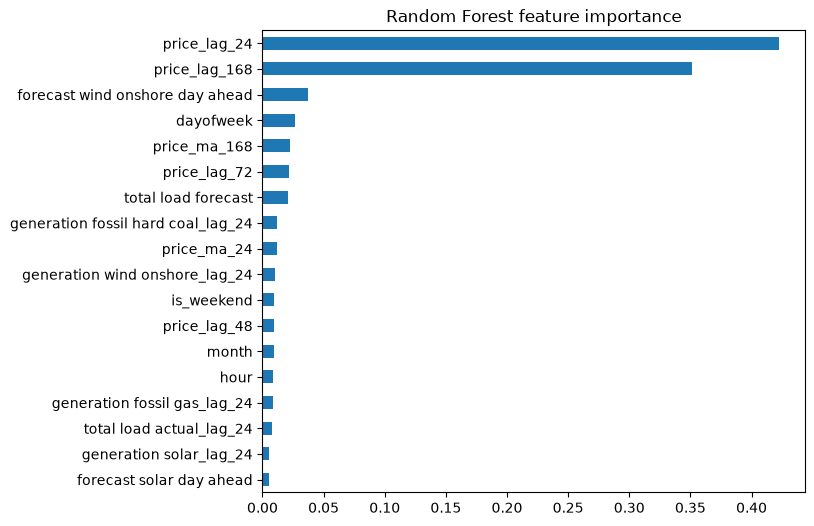

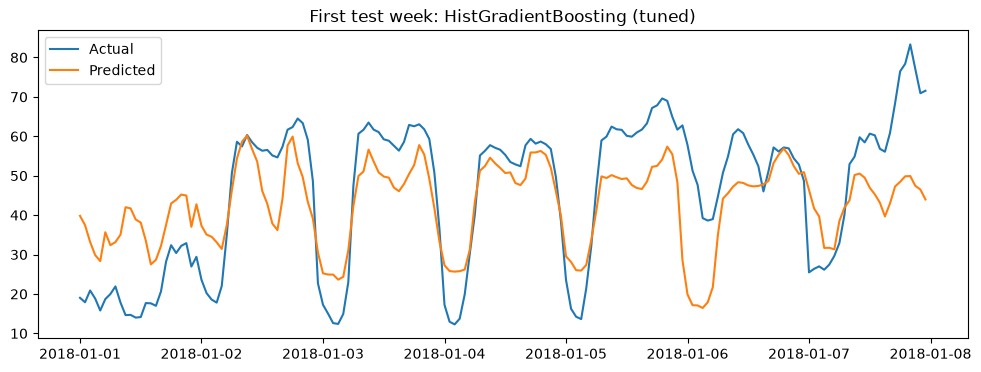

In [10]:
rf, rf_feats = searches["random_forest"]
pd.Series(rf.best_estimator_.feature_importances_, index=rf_feats).sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Random Forest feature importance")
plt.savefig("../reports/figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

best, best_feats = searches[chosen][0].best_estimator_, searches[chosen][1]
week = y_test.iloc[:24*7]
plt.figure(figsize=(12, 4))
plt.plot(week, label="Actual")
plt.plot(week.index, best.predict(X_test[best_feats].iloc[:24*7]), label="Predicted")
plt.title(f"First test week: {EXPERIMENTS[chosen][0]}")
plt.legend()
plt.savefig("../reports/figures/predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

save_model(best, best_feats, "../models/price_model.joblib")